In [4]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

# Create output directory
import os
os.makedirs('../reports/EDA', exist_ok=True)

print("="*70)
print("FRAUD DETECTION DATASET - EXPLORATORY DATA ANALYSIS")
print("Bangladesh Mobile Banking (bKash)")
print("="*70)



print("\n[1] Loading dataset...")

# From notebooks/ to src/data/
df = pd.read_csv('../src/data/transactions.csv')
users = pd.read_csv('../src/data/users.csv')
merchants = pd.read_csv('../src/data/merchants.csv')
failed = pd.read_csv('../src/data/failed_transactions.csv')

df.head()

FRAUD DETECTION DATASET - EXPLORATORY DATA ANALYSIS
Bangladesh Mobile Banking (bKash)

[1] Loading dataset...


,transaction_id,user_id,merchant_id,amount,hour,day,location,device_id,timestamp,user_segment,...,velocity_1hr,unique_merchants_today,unique_locations_today,device_change_flag,new_device_flag,new_location_flag,location_change_flag,merchant_change_flag,anomaly_score,anomaly_signals
0,T000000,U03858,M0292,376.39,1,0,Rangpur,D18051,2024-01-01 01:34:00,office_worker,...,4,1,1,0,0,0,1,1,0.4,"['non_home_location', 'unusual_hour', 'new_mer..."
1,T000001,U01731,M0067,6211.41,3,0,Chattogram,D22438,2024-01-01 03:13:00,merchant,...,1,1,1,0,0,0,0,1,0.2,"['unusual_hour', 'new_merchant']"
2,T000002,U00342,M0465,11067.46,3,0,Rajshahi,D41975,2024-01-01 03:21:00,office_worker,...,2,1,1,0,0,0,0,1,0.2,"['new_merchant', 'new_category']"
3,T000003,U01483,M0042,133.74,4,0,Khulna,D3840,2024-01-01 04:56:00,farmer,...,2,1,1,0,0,0,0,0,0.1,['unusual_hour']
4,T000004,U02893,M0320,932.71,5,0,Mymensingh,D28635,2024-01-01 05:53:00,office_worker,...,3,1,1,0,0,0,1,0,0.2,"['non_home_location', 'unusual_hour']"



[2] Class Distribution...


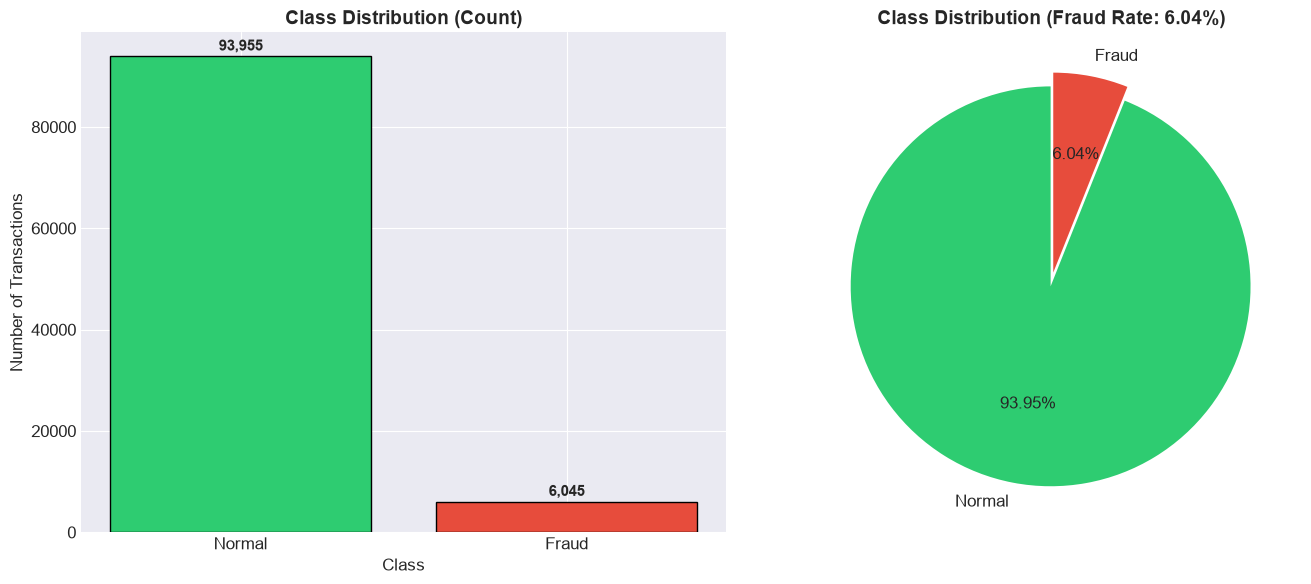

  Normal: 93,955 (93.95%)
  Fraud:  6,045 (6.04%)
  Fraud Rate: 6.04%


In [5]:
# ================================================================
# 2. CLASS DISTRIBUTION
# ================================================================

print("\n[2] Class Distribution...")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Count plot
fraud_counts = df['fraud_label'].value_counts()
colors = ['#2ecc71', '#e74c3c']
bars = axes[0].bar(['Normal', 'Fraud'], fraud_counts.values, color=colors, edgecolor='black')
axes[0].set_title('Class Distribution (Count)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Transactions')
axes[0].set_xlabel('Class')

for bar, count in zip(bars, fraud_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                f'{count:,}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Pie chart
fraud_rate = df['fraud_label'].mean() * 100
axes[1].pie(fraud_counts.values, labels=['Normal', 'Fraud'], autopct='%1.2f%%',
           colors=colors, startangle=90, explode=(0.02, 0.05))
axes[1].set_title(f'Class Distribution (Fraud Rate: {fraud_rate:.2f}%)', 
                  fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/EDA/class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"  Normal: {fraud_counts[0]:,} ({fraud_counts[0]/len(df)*100:.2f}%)")
print(f"  Fraud:  {fraud_counts[1]:,} ({fraud_counts[1]/len(df)*100:.2f}%)")
print(f"  Fraud Rate: {fraud_rate:.2f}%")


[3] Fraud Type Distribution...


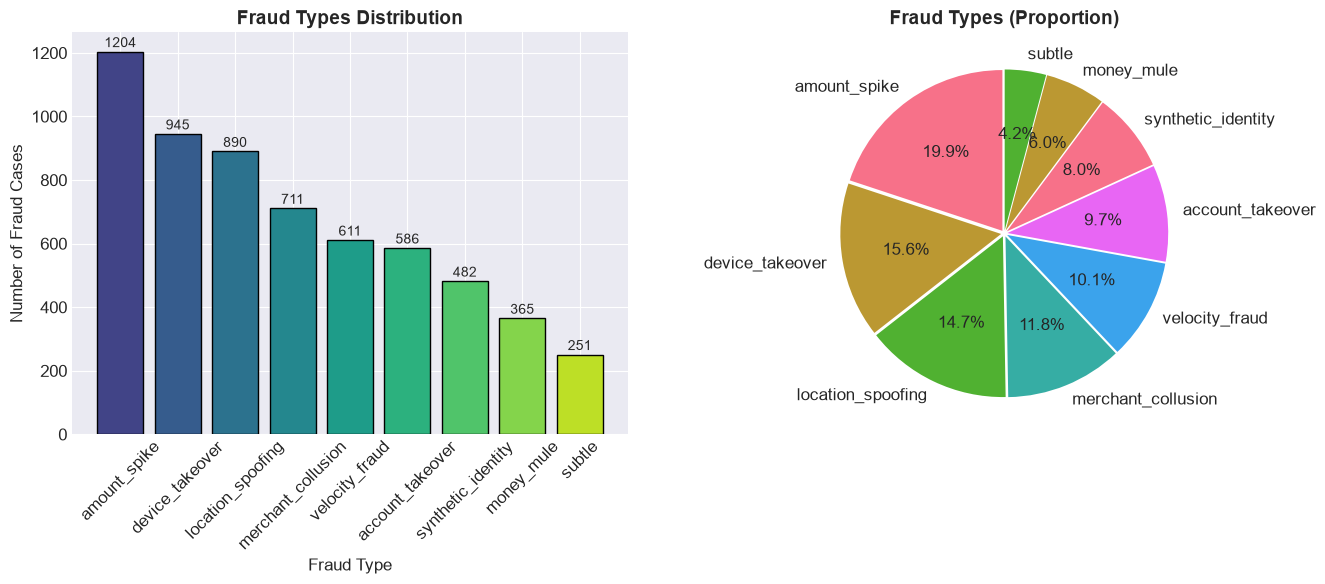

Fraud Type Distribution:
  amount_spike: 1,204 (19.9%)
  device_takeover: 945 (15.6%)
  location_spoofing: 890 (14.7%)
  merchant_collusion: 711 (11.8%)
  velocity_fraud: 611 (10.1%)
  account_takeover: 586 (9.7%)
  synthetic_identity: 482 (8.0%)
  money_mule: 365 (6.0%)
  subtle: 251 (4.2%)


In [6]:
# ================================================================
# 3. FRAUD TYPE DISTRIBUTION
# ================================================================

print("\n[3] Fraud Type Distribution...")

fraud_df = df[df['fraud_label'] == 1]
fraud_types = fraud_df['fraud_type'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Bar plot
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(fraud_types)))
bars = axes[0].bar(fraud_types.index, fraud_types.values, color=colors, edgecolor='black')
axes[0].set_title('Fraud Types Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Fraud Cases')
axes[0].set_xlabel('Fraud Type')
axes[0].tick_params(axis='x', rotation=45)

for bar, count in zip(bars, fraud_types.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                f'{count}', ha='center', va='bottom', fontsize=10)

# Pie chart
axes[1].pie(fraud_types.values, labels=fraud_types.index, autopct='%1.1f%%',
           startangle=90, explode=[0.02]*len(fraud_types))
axes[1].set_title('Fraud Types (Proportion)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/EDA/fraud_type_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Fraud Type Distribution:")
for ftype, count in fraud_types.items():
    print(f"  {ftype}: {count:,} ({count/len(fraud_df)*100:.1f}%)")


[4] Amount Distribution...


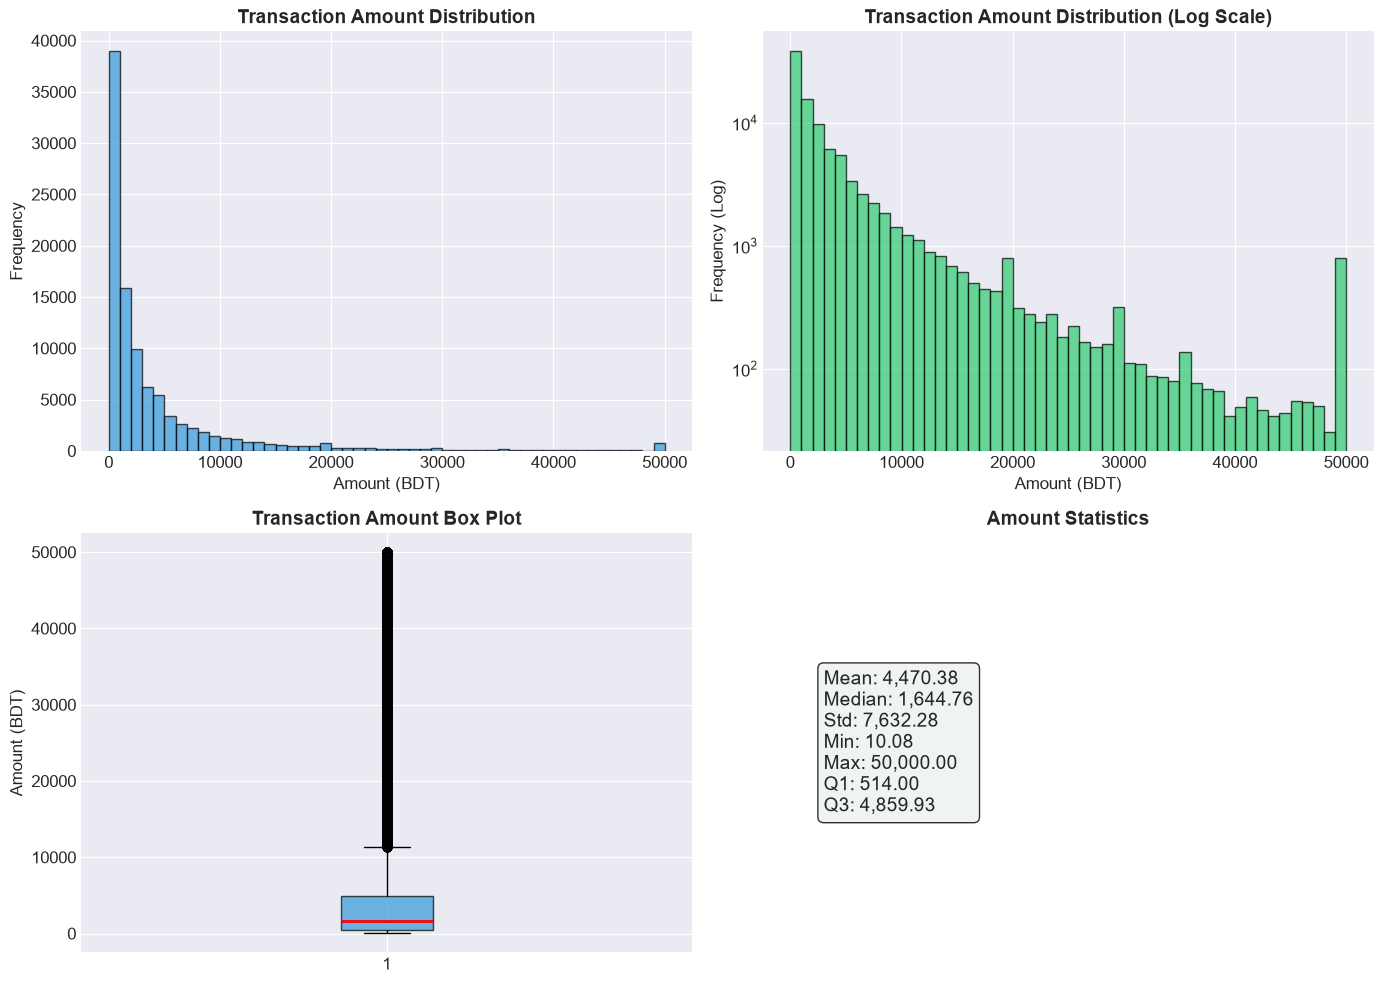

Amount Statistics:
count    100000.000000
mean       4470.378121
std        7632.277021
min          10.080000
25%         514.000000
50%        1644.760000
75%        4859.927500
max       50000.000000


In [7]:
# ================================================================
# 4. AMOUNT DISTRIBUTION
# ================================================================

print("\n[4] Amount Distribution...")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histogram
axes[0, 0].hist(df['amount'], bins=50, color='#3498db', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Transaction Amount Distribution', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Amount (BDT)')
axes[0, 0].set_ylabel('Frequency')

# Log scale histogram
axes[0, 1].hist(df['amount'], bins=50, color='#2ecc71', edgecolor='black', alpha=0.7, log=True)
axes[0, 1].set_title('Transaction Amount Distribution (Log Scale)', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Amount (BDT)')
axes[0, 1].set_ylabel('Frequency (Log)')

# Box plot
bp = axes[1, 0].boxplot(df['amount'], patch_artist=True,
                        boxprops=dict(facecolor='#3498db', alpha=0.7),
                        medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_title('Transaction Amount Box Plot', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Amount (BDT)')

# Statistics
stats_text = f"Mean: {df['amount'].mean():,.2f}\n"
stats_text += f"Median: {df['amount'].median():,.2f}\n"
stats_text += f"Std: {df['amount'].std():,.2f}\n"
stats_text += f"Min: {df['amount'].min():,.2f}\n"
stats_text += f"Max: {df['amount'].max():,.2f}\n"
stats_text += f"Q1: {df['amount'].quantile(0.25):,.2f}\n"
stats_text += f"Q3: {df['amount'].quantile(0.75):,.2f}"

axes[1, 1].text(0.1, 0.5, stats_text, fontsize=14, verticalalignment='center',
                bbox=dict(boxstyle='round', facecolor='#ecf0f1', alpha=0.8))
axes[1, 1].axis('off')
axes[1, 1].set_title('Amount Statistics', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/EDA/amount_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Amount Statistics:")
print(df['amount'].describe().to_string())


[5] Fraud vs Non-Fraud Amounts...


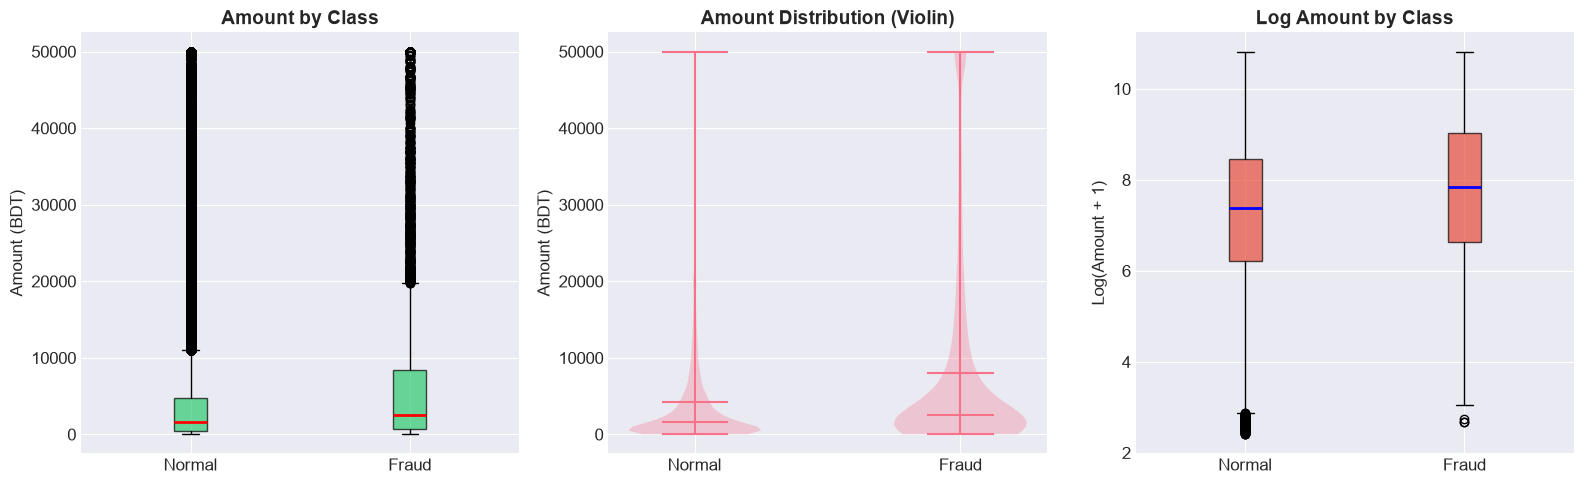

Amount Statistics by Class:
               count         mean           std    min     25%      50%       75%      max
fraud_label                                                                               
0            93955.0  4238.797539   7115.972306  10.08  503.67  1601.08  4701.295  50000.0
1             6045.0  8069.741820  12760.833995  13.47  760.19  2537.94  8368.680  50000.0

Fraud is 1.9x larger than normal


In [9]:
# ================================================================
# 5. FRAUD vs NON-FRAUD AMOUNTS
# ================================================================

print("\n[5] Fraud vs Non-Fraud Amounts...")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Box plot - FIXED
data = [df[df['fraud_label'] == 0]['amount'], df[df['fraud_label'] == 1]['amount']]
bp = axes[0].boxplot(data, patch_artist=True,
                     boxprops=dict(facecolor='#2ecc71', alpha=0.7),
                     medianprops=dict(color='red', linewidth=2))
# Set labels after creating boxplot
axes[0].set_xticklabels(['Normal', 'Fraud'])
axes[0].set_title('Amount by Class', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Amount (BDT)')

# Violin plot
violin_data = [df[df['fraud_label'] == 0]['amount'], df[df['fraud_label'] == 1]['amount']]
axes[1].violinplot(violin_data, showmeans=True, showmedians=True)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(['Normal', 'Fraud'])
axes[1].set_title('Amount Distribution (Violin)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Amount (BDT)')

# Log scale box plot - FIXED
log_data = [np.log1p(df[df['fraud_label'] == 0]['amount']),
            np.log1p(df[df['fraud_label'] == 1]['amount'])]
bp = axes[2].boxplot(log_data, patch_artist=True,
                     boxprops=dict(facecolor='#e74c3c', alpha=0.7),
                     medianprops=dict(color='blue', linewidth=2))
axes[2].set_xticklabels(['Normal', 'Fraud'])
axes[2].set_title('Log Amount by Class', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Log(Amount + 1)')

plt.tight_layout()
plt.savefig('../reports/EDA/fraud_vs_normal_amounts.png', dpi=300, bbox_inches='tight')
plt.show()

print("Amount Statistics by Class:")
print(df.groupby('fraud_label')['amount'].describe().to_string())
print(f"\nFraud is {df[df['fraud_label']==1]['amount'].mean() / df[df['fraud_label']==0]['amount'].mean():.1f}x larger than normal")


[6] Merchant Categories...


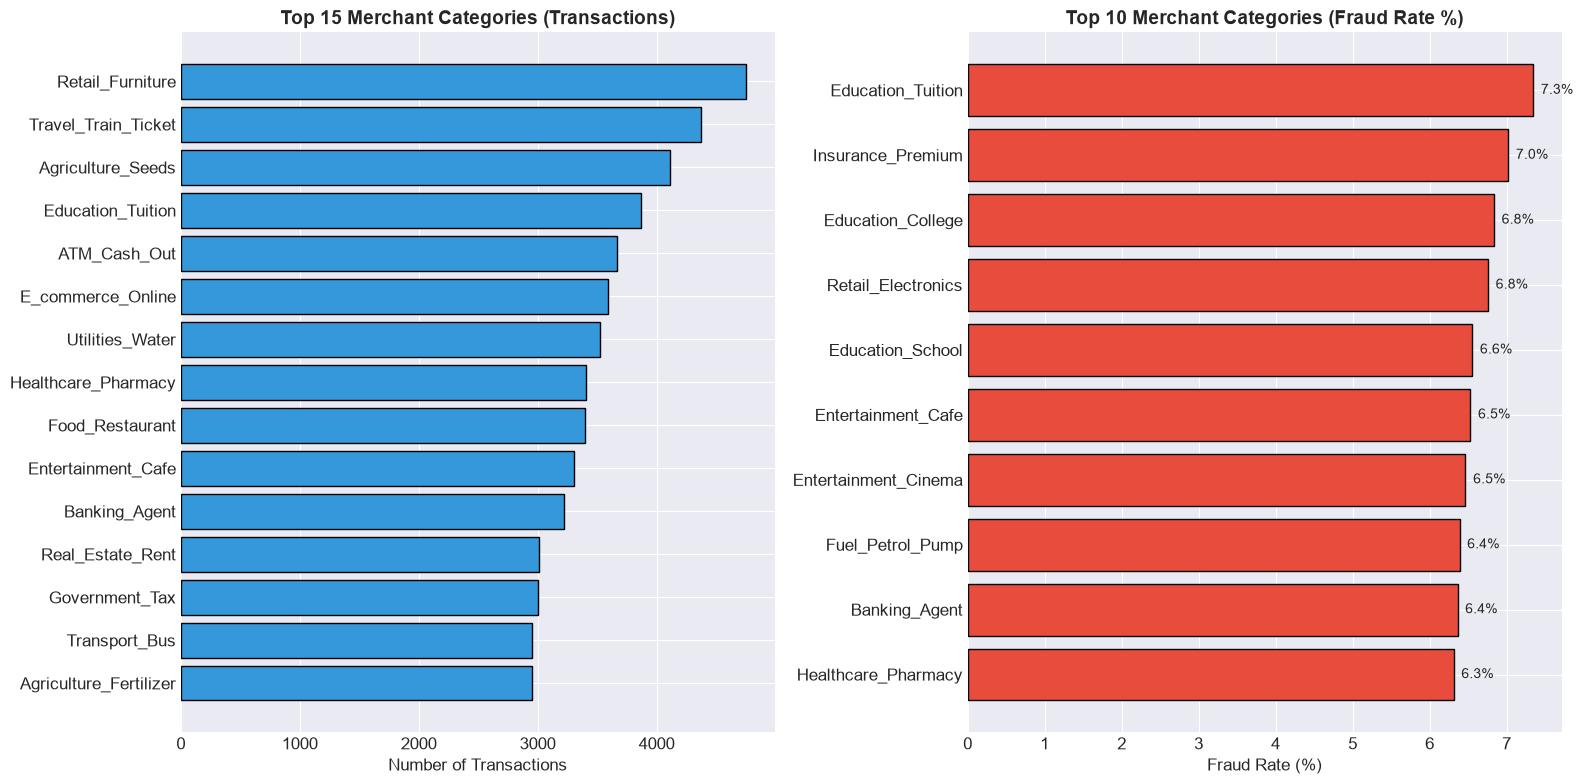

Top 10 Merchant Categories (Fraud Rate):
  Education_Tuition: 7.35%
  Insurance_Premium: 7.02%
  Education_College: 6.84%
  Retail_Electronics: 6.76%
  Education_School: 6.55%
  Entertainment_Cafe: 6.53%
  Entertainment_Cinema: 6.47%
  Fuel_Petrol_Pump: 6.39%
  Banking_Agent: 6.36%
  Healthcare_Pharmacy: 6.31%


In [10]:
# ================================================================
# 6. MERCHANT CATEGORIES
# ================================================================

print("\n[6] Merchant Categories...")

merchant_counts = df['merchant_category'].value_counts()
fraud_by_merchant = df[df['fraud_label'] == 1]['merchant_category'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Top merchants by transaction count
top_merchants = merchant_counts.head(15)
bars = axes[0].barh(top_merchants.index, top_merchants.values, color='#3498db', edgecolor='black')
axes[0].set_title('Top 15 Merchant Categories (Transactions)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Transactions')
axes[0].invert_yaxis()

# Fraud rate by merchant category
merchant_fraud_rate = df.groupby('merchant_category')['fraud_label'].mean().sort_values(ascending=False)
top_fraud_merchants = merchant_fraud_rate.head(10)
bars = axes[1].barh(top_fraud_merchants.index, top_fraud_merchants.values * 100,
                    color='#e74c3c', edgecolor='black')
axes[1].set_title('Top 10 Merchant Categories (Fraud Rate %)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Fraud Rate (%)')
axes[1].invert_yaxis()

for bar, rate in zip(bars, top_fraud_merchants.values):
    axes[1].text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
                f'{rate*100:.1f}%', va='center', fontsize=10)

plt.tight_layout()
plt.savefig('../reports/EDA/merchant_categories.png', dpi=300, bbox_inches='tight')
plt.show()

print("Top 10 Merchant Categories (Fraud Rate):")
for cat, rate in top_fraud_merchants.head(10).items():
    print(f"  {cat}: {rate*100:.2f}%")


[7] User Segments...


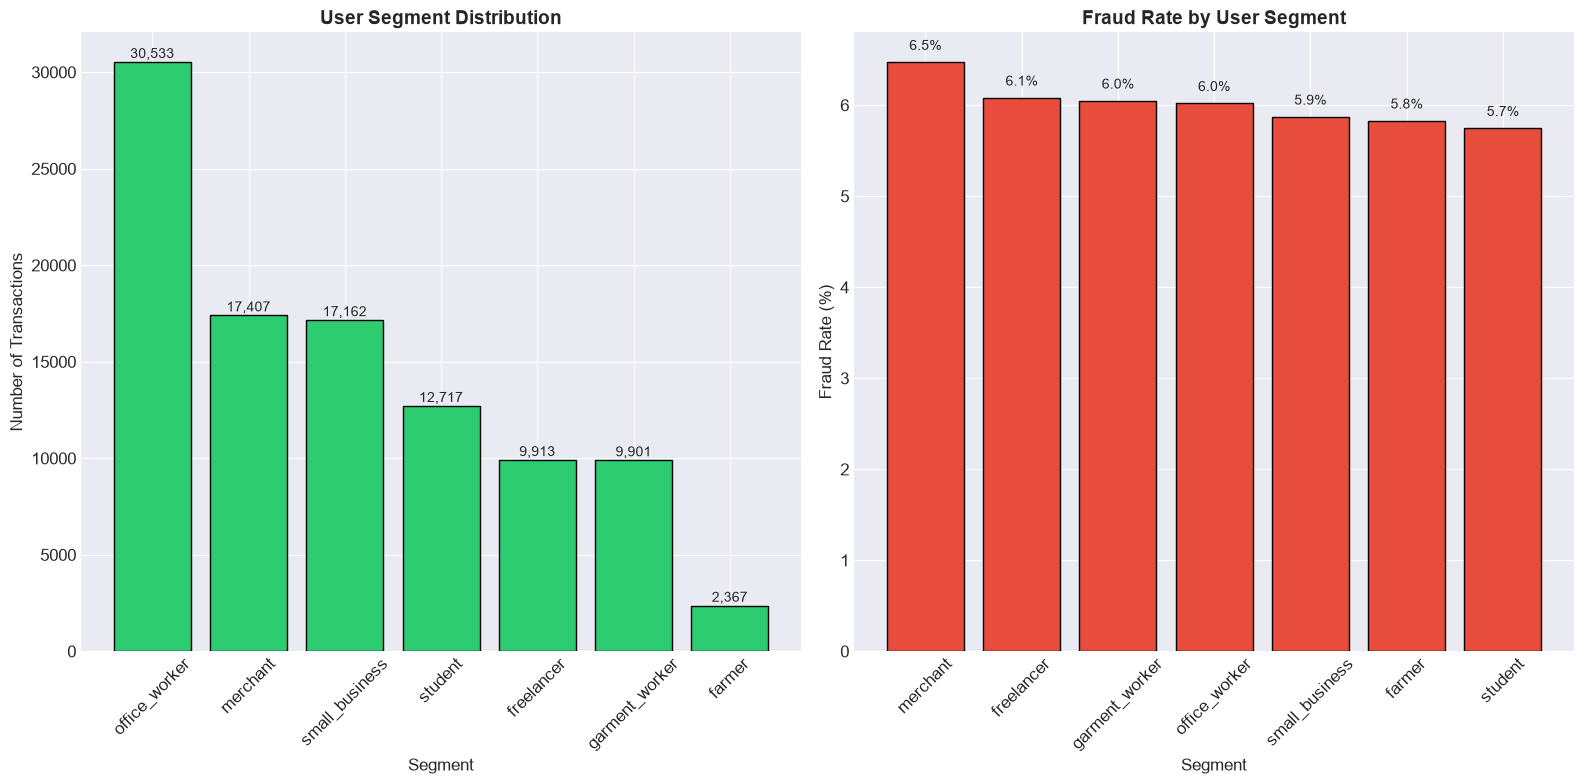

Fraud Rate by User Segment:
  merchant: 6.47%
  freelancer: 6.08%
  garment_worker: 6.05%
  office_worker: 6.02%
  small_business: 5.87%
  farmer: 5.83%
  student: 5.75%


In [11]:
# ================================================================
# 7. USER SEGMENTS
# ================================================================

print("\n[7] User Segments...")

user_counts = df['user_segment'].value_counts()
fraud_by_segment = df[df['fraud_label'] == 1]['user_segment'].value_counts()
segment_fraud_rate = df.groupby('user_segment')['fraud_label'].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Segment distribution
bars = axes[0].bar(user_counts.index, user_counts.values, color='#2ecc71', edgecolor='black')
axes[0].set_title('User Segment Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Transactions')
axes[0].set_xlabel('Segment')
axes[0].tick_params(axis='x', rotation=45)

for bar, count in zip(bars, user_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                f'{count:,}', ha='center', va='bottom', fontsize=10)

# Fraud rate by segment
segment_fraud_sorted = segment_fraud_rate.sort_values(ascending=False)
bars = axes[1].bar(segment_fraud_sorted.index, segment_fraud_sorted.values * 100,
                   color='#e74c3c', edgecolor='black')
axes[1].set_title('Fraud Rate by User Segment', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Fraud Rate (%)')
axes[1].set_xlabel('Segment')
axes[1].tick_params(axis='x', rotation=45)

for bar, rate in zip(bars, segment_fraud_sorted.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                f'{rate*100:.1f}%', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('../reports/EDA/user_segments.png', dpi=300, bbox_inches='tight')
plt.show()

print("Fraud Rate by User Segment:")
for seg, rate in segment_fraud_sorted.items():
    print(f"  {seg}: {rate*100:.2f}%")


[8] Fraud by Hour...


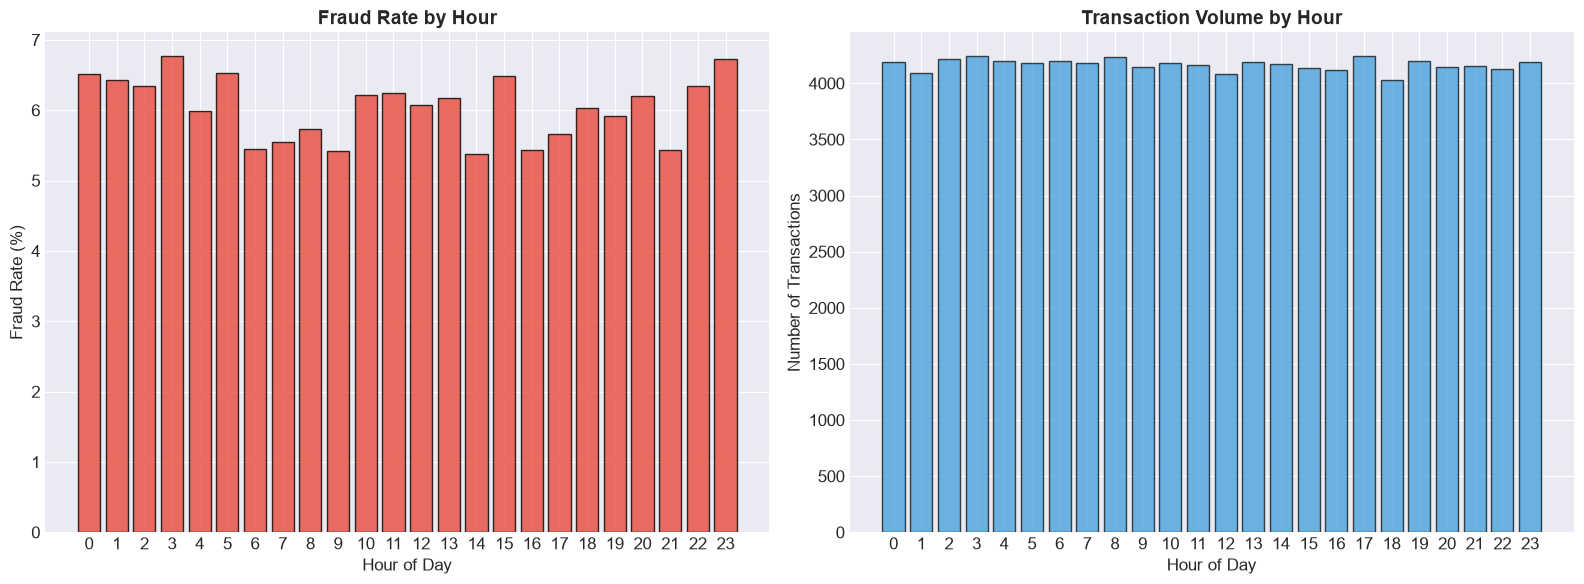

Peak Fraud Hours:
  Hour 3:00: 6.77%
  Hour 23:00: 6.74%
  Hour 5:00: 6.52%
  Hour 0:00: 6.52%
  Hour 15:00: 6.48%

Peak Transaction Hours:
  Hour 3:00: 4,241 transactions
  Hour 17:00: 4,240 transactions
  Hour 8:00: 4,234 transactions
  Hour 2:00: 4,221 transactions
  Hour 6:00: 4,200 transactions


In [12]:
# ================================================================
# 8. FRAUD BY HOUR
# ================================================================

print("\n[8] Fraud by Hour...")

hourly_fraud = df.groupby('hour')['fraud_label'].mean()
hourly_counts = df.groupby('hour').size()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Fraud rate by hour
bars = axes[0].bar(hourly_fraud.index, hourly_fraud.values * 100,
                   color='#e74c3c', edgecolor='black', alpha=0.8)
axes[0].set_title('Fraud Rate by Hour', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Fraud Rate (%)')
axes[0].set_xticks(range(0, 24))

# Transaction counts by hour
bars = axes[1].bar(hourly_counts.index, hourly_counts.values,
                   color='#3498db', edgecolor='black', alpha=0.7)
axes[1].set_title('Transaction Volume by Hour', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Number of Transactions')
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.savefig('../reports/EDA/fraud_by_hour.png', dpi=300, bbox_inches='tight')
plt.show()

print("Peak Fraud Hours:")
peak_hours = hourly_fraud.nlargest(5)
for hour, rate in peak_hours.items():
    print(f"  Hour {hour}:00: {rate*100:.2f}%")

print("\nPeak Transaction Hours:")
peak_txn = hourly_counts.nlargest(5)
for hour, count in peak_txn.items():
    print(f"  Hour {hour}:00: {count:,} transactions")


[10] Fraud by User Risk...


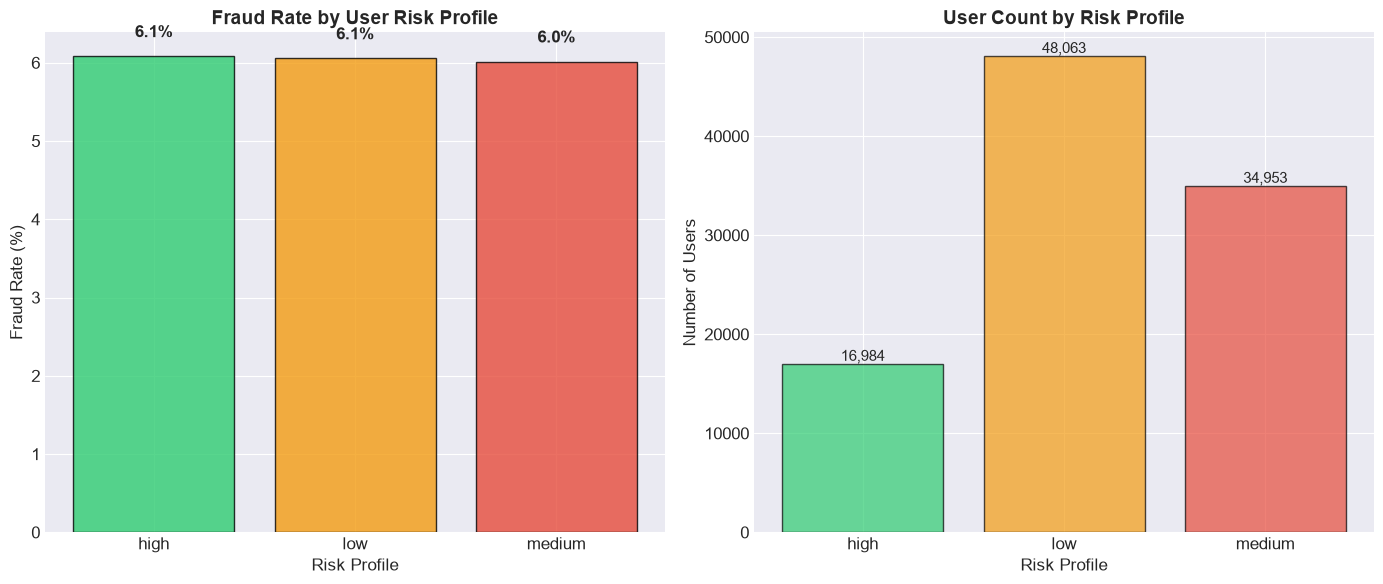

Fraud Rate by User Risk:
  high: 6.08% (16,984 users)
  low: 6.05% (48,063 users)
  medium: 6.01% (34,953 users)


In [13]:
# ================================================================
# 10. FRAUD BY USER RISK
# ================================================================

print("\n[10] Fraud by User Risk...")

risk_fraud = df.groupby('user_risk')['fraud_label'].mean()
risk_counts = df.groupby('user_risk').size()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Fraud rate by user risk
colors = ['#2ecc71', '#f39c12', '#e74c3c']
bars = axes[0].bar(risk_fraud.index, risk_fraud.values * 100,
                   color=colors, edgecolor='black', alpha=0.8)
axes[0].set_title('Fraud Rate by User Risk Profile', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Fraud Rate (%)')
axes[0].set_xlabel('Risk Profile')

for bar, rate in zip(bars, risk_fraud.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                f'{rate*100:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

# Distribution of users by risk
bars = axes[1].bar(risk_counts.index, risk_counts.values,
                   color=colors, edgecolor='black', alpha=0.7)
axes[1].set_title('User Count by Risk Profile', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Number of Users')
axes[1].set_xlabel('Risk Profile')

for bar, count in zip(bars, risk_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                f'{count:,}', ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.savefig('../reports/EDA/fraud_by_user_risk.png', dpi=300, bbox_inches='tight')
plt.show()

print("Fraud Rate by User Risk:")
for risk, rate in risk_fraud.items():
    print(f"  {risk}: {rate*100:.2f}% ({risk_counts[risk]:,} users)")


[11] Fraud by Merchant Risk...


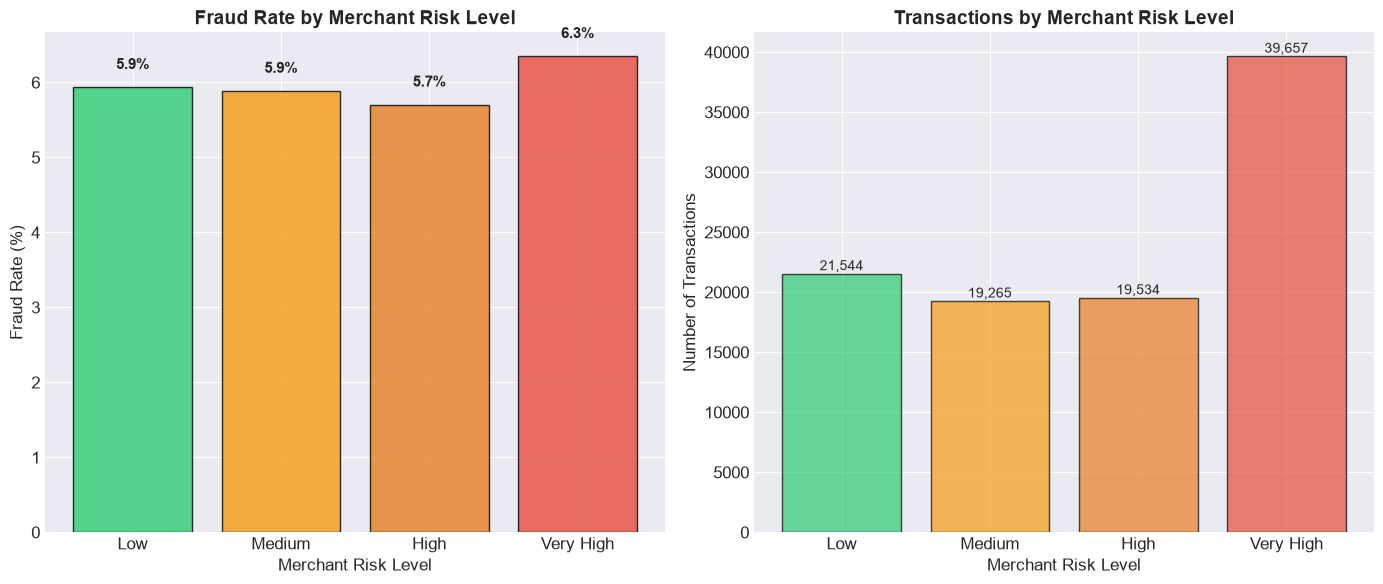

Fraud Rate by Merchant Risk Level:
  Low: 5.94% (21,544 transactions)
  Medium: 5.89% (19,265 transactions)
  High: 5.70% (19,534 transactions)
  Very High: 6.35% (39,657 transactions)


In [15]:
# ================================================================
# 11. FRAUD BY MERCHANT RISK
# ================================================================

print("\n[11] Fraud by Merchant Risk...")

# Binning merchant risk
df['merchant_risk_bin'] = pd.cut(df['merchant_risk'], bins=[0, 0.3, 0.5, 0.7, 1.0],
                                  labels=['Low', 'Medium', 'High', 'Very High'])

risk_bin_fraud = df.groupby('merchant_risk_bin')['fraud_label'].mean()
risk_bin_counts = df.groupby('merchant_risk_bin').size()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Fraud rate by merchant risk bin
colors = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']
bars = axes[0].bar(risk_bin_fraud.index, risk_bin_fraud.values * 100,
                   color=colors, edgecolor='black', alpha=0.8)
axes[0].set_title('Fraud Rate by Merchant Risk Level', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Fraud Rate (%)')
axes[0].set_xlabel('Merchant Risk Level')

for bar, rate in zip(bars, risk_bin_fraud.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                f'{rate*100:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Transaction count by merchant risk
bars = axes[1].bar(risk_bin_counts.index, risk_bin_counts.values,
                   color=colors, edgecolor='black', alpha=0.7)
axes[1].set_title('Transactions by Merchant Risk Level', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Number of Transactions')
axes[1].set_xlabel('Merchant Risk Level')

for bar, count in zip(bars, risk_bin_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                f'{count:,}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('../reports/EDA/fraud_by_merchant_risk.png', dpi=300, bbox_inches='tight')
plt.show()

print("Fraud Rate by Merchant Risk Level:")
for risk, rate in risk_bin_fraud.items():
    print(f"  {risk}: {rate*100:.2f}% ({risk_bin_counts[risk]:,} transactions)")


[12] Correlation Heatmap...


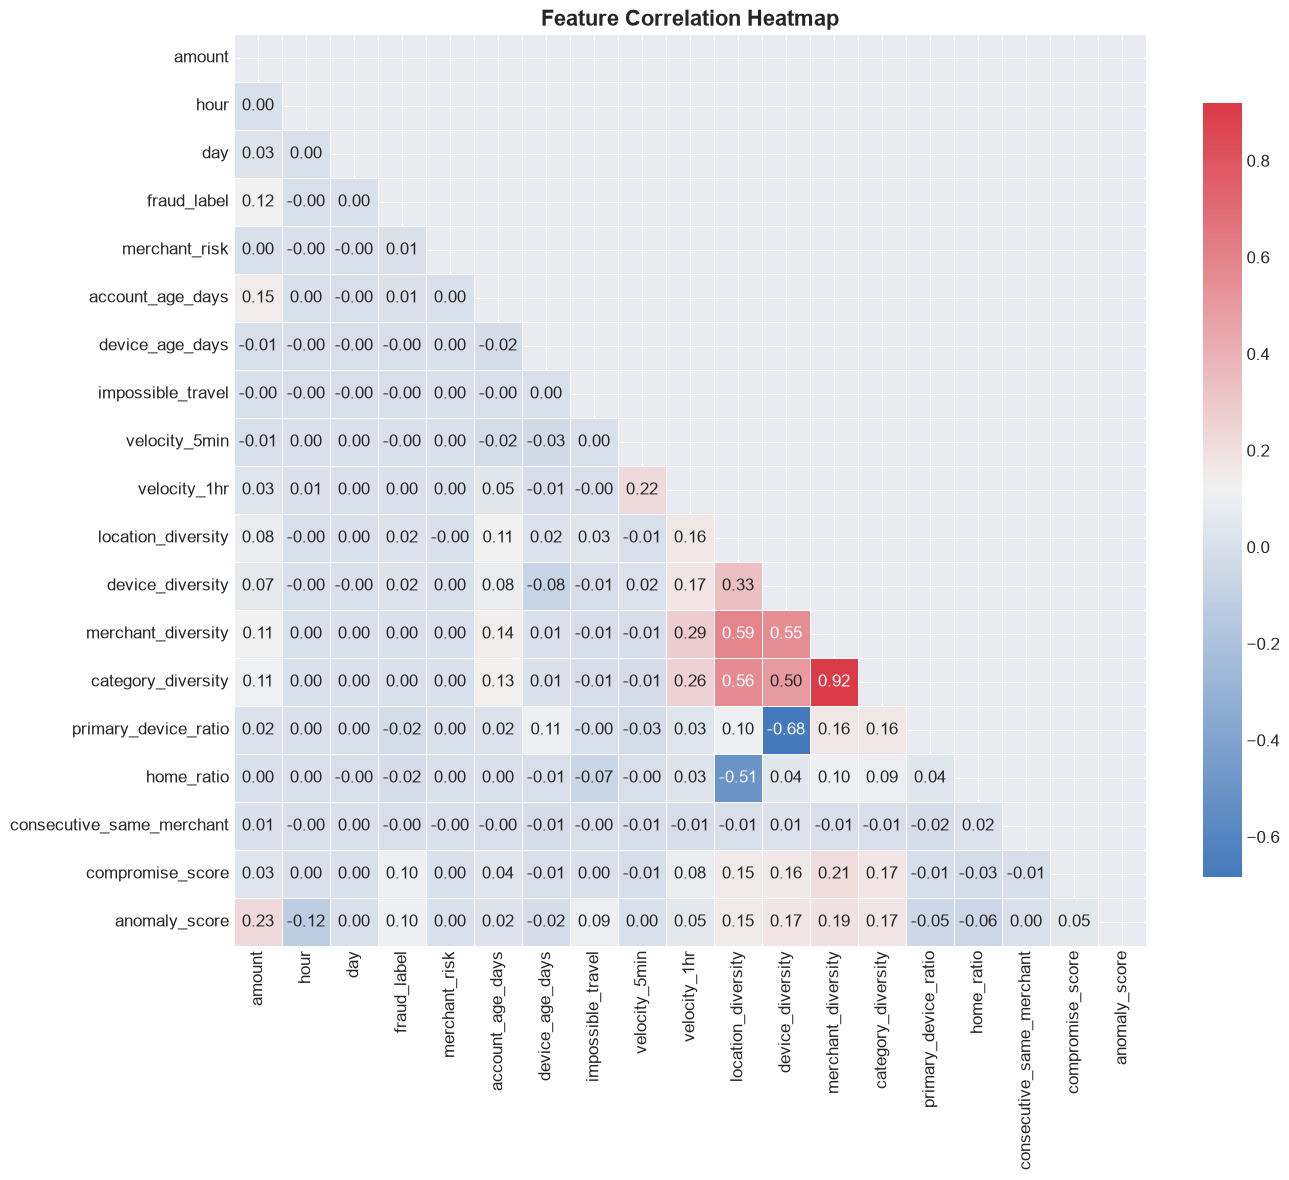

Top Features Correlated with Fraud:
  amount: 0.120
  anomaly_score: 0.103
  compromise_score: 0.099
  device_diversity: 0.020
  location_diversity: 0.017
  account_age_days: 0.006
  merchant_risk: 0.005
  merchant_diversity: 0.004
  category_diversity: 0.003


In [16]:
# ================================================================
# 12. CORRELATION HEATMAP
# ================================================================

print("\n[12] Correlation Heatmap...")

# Select numeric columns
numeric_cols = ['amount', 'hour', 'day', 'fraud_label', 'merchant_risk',
                'account_age_days', 'device_age_days', 'impossible_travel',
                'velocity_5min', 'velocity_1hr', 'location_diversity',
                'device_diversity', 'merchant_diversity', 'category_diversity',
                'primary_device_ratio', 'home_ratio', 'consecutive_same_merchant',
                'compromise_score', 'anomaly_score']

# Filter columns that exist
existing_cols = [col for col in numeric_cols if col in df.columns]
corr_df = df[existing_cols].corr()

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_df, dtype=bool))
cmap = sns.diverging_palette(250, 10, as_cmap=True)

sns.heatmap(corr_df, mask=mask, annot=True, fmt='.2f', cmap=cmap,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            ax=ax)
ax.set_title('Feature Correlation Heatmap', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/EDA/correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# Top correlations with fraud
fraud_corr = corr_df['fraud_label'].sort_values(ascending=False)
print("Top Features Correlated with Fraud:")
for feat, corr in fraud_corr.head(10).items():
    if feat != 'fraud_label':
        print(f"  {feat}: {corr:.3f}")


[13] Missing Values...


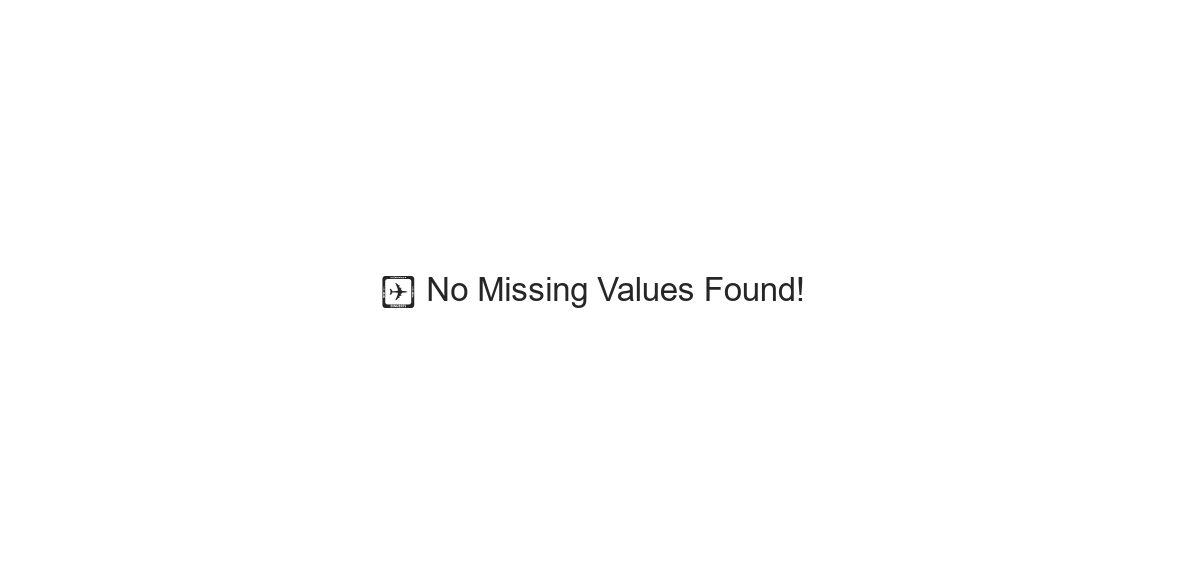

Total missing values: 0
✅ Dataset has no missing values!


In [17]:
# ================================================================
# 13. MISSING VALUES
# ================================================================

print("\n[13] Missing Values...")

missing = df.isnull().sum()
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(12, 6))

if len(missing) > 0:
    bars = ax.bar(missing.index, missing.values, color='#e74c3c', edgecolor='black')
    ax.set_title('Missing Values by Column', fontsize=14, fontweight='bold')
    ax.set_ylabel('Number of Missing Values')
    ax.set_xlabel('Column')
    ax.tick_params(axis='x', rotation=45)

    for bar, count in zip(bars, missing.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                f'{count}', ha='center', va='bottom', fontsize=10)
else:
    ax.text(0.5, 0.5, '✅ No Missing Values Found!', 
            fontsize=24, ha='center', va='center', transform=ax.transAxes)
    ax.axis('off')

plt.tight_layout()
plt.savefig('../reports/EDA/missing_values.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Total missing values: {df.isnull().sum().sum()}")
if df.isnull().sum().sum() == 0:
    print("✅ Dataset has no missing values!")

In [18]:
# ================================================================
# 14. SUMMARY STATISTICS
# ================================================================

print("\n[14] Summary Statistics...")

print("="*70)
print("DATASET SUMMARY")
print("="*70)

print(f"\n📊 Dataset Size: {len(df):,} transactions")
print(f"👤 Users: {len(users):,}")
print(f"🏪 Merchants: {len(merchants):,}")
print(f"📁 Features: {len(df.columns)}")

print("\n📈 Fraud Statistics:")
print(f"  Fraud Rate: {df['fraud_label'].mean()*100:.2f}%")
print(f"  Total Fraud Cases: {df['fraud_label'].sum():,}")
print(f"  Total Normal Cases: {len(df) - df['fraud_label'].sum():,}")

print("\n💰 Amount Statistics:")
print(f"  Mean Amount: {df['amount'].mean():,.2f} BDT")
print(f"  Median Amount: {df['amount'].median():,.2f} BDT")
print(f"  Max Amount: {df['amount'].max():,.2f} BDT")
print(f"  Min Amount: {df['amount'].min():,.2f} BDT")

print("\n🎯 Fraud Amount Statistics:")
fraud_amounts = df[df['fraud_label'] == 1]['amount']
normal_amounts = df[df['fraud_label'] == 0]['amount']
print(f"  Fraud Mean: {fraud_amounts.mean():,.2f} BDT")
print(f"  Normal Mean: {normal_amounts.mean():,.2f} BDT")
print(f"  Fraud/Normal Ratio: {fraud_amounts.mean() / normal_amounts.mean():.2f}x")

print("\n🕐 Time Statistics:")
print(f"  Hours Range: 0-23")
print(f"  Days Range: 0-6 (Monday-Sunday)")

# Generate report summary
summary_df = pd.DataFrame({
    'Metric': ['Total Transactions', 'Total Users', 'Total Merchants', 'Fraud Rate',
               'Total Fraud', 'Total Normal', 'Mean Amount', 'Median Amount',
               'Max Amount', 'Min Amount', 'Fraud Mean Amount', 'Normal Mean Amount'],
    'Value': [
        f"{len(df):,}",
        f"{len(users):,}",
        f"{len(merchants):,}",
        f"{df['fraud_label'].mean()*100:.2f}%",
        f"{df['fraud_label'].sum():,}",
        f"{len(df) - df['fraud_label'].sum():,}",
        f"{df['amount'].mean():,.2f}",
        f"{df['amount'].median():,.2f}",
        f"{df['amount'].max():,.2f}",
        f"{df['amount'].min():,.2f}",
        f"{fraud_amounts.mean():,.2f}",
        f"{normal_amounts.mean():,.2f}"
    ]
})

summary_df.to_csv('../reports/EDA/dataset_summary.csv', index=False)
print("\n✅ Summary saved to reports/EDA/dataset_summary.csv")


[14] Summary Statistics...
DATASET SUMMARY

📊 Dataset Size: 100,000 transactions
👤 Users: 5,000
🏪 Merchants: 500
📁 Features: 43

📈 Fraud Statistics:
  Fraud Rate: 6.04%
  Total Fraud Cases: 6,045
  Total Normal Cases: 93,955

💰 Amount Statistics:
  Mean Amount: 4,470.38 BDT
  Median Amount: 1,644.76 BDT
  Max Amount: 50,000.00 BDT
  Min Amount: 10.08 BDT

🎯 Fraud Amount Statistics:
  Fraud Mean: 8,069.74 BDT
  Normal Mean: 4,238.80 BDT
  Fraud/Normal Ratio: 1.90x

🕐 Time Statistics:
  Hours Range: 0-23
  Days Range: 0-6 (Monday-Sunday)

✅ Summary saved to reports/EDA/dataset_summary.csv
